# The Rosin-Rammler feed on the sieve grid: what x63 and m do to F80

**Question:** How do the two Rosin-Rammler parameters of a feed set the F80 that the crusher engine sees, and why is that F80 not the one the textbook formula gives?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 01-getting-started
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can:

- write the Rosin-Rammler law, say what x63 and m mean, and draw the feed they describe;
- discretise the law on the engine's sieve grid and read F80 from it by interpolation;
- compare that F80 with the closed-form one from an oracle that shares no code with the engine;
- explain the gap between the two: the engine's grid stops at 256 mm, and the mass above it is not in the feed.

## Setup

Same environment as the rest of the set: numpy for the arrays, matplotlib for the figures.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Two sets of imports matter here. The feed generator and the sieve utilities come from the engine's modules. The closed-form law comes from `data-pipeline/pipeline/oracles.py`, which states the Rosin-Rammler relations from the textbook and shares no code with the engine; its functions are imported under other names so they cannot be confused with the engine's.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher.feed import make_feed
from pipeline.model.crusher.sieve import make_grid, size_at_passing, passing_at_size
from pipeline.oracles import rosin_rammler_passing as law_passing
from pipeline.oracles import rosin_rammler_size_at as law_size_at
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

This notebook needs no measurement: the feed of the reference case S01 gives the two parameters. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params` (`feed_x63_mm` and `feed_m`).

The next cell reads the two parameters of S01.

In [2]:
# Read the feed parameters of the reference case
params = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"]
X63, M = params["feed_x63_mm"], params["feed_m"]
print(f"x63 = {X63} mm, m = {M}")

x63 = 90.0 mm, m = 1.2


## Method

**Step 1, the law.** Rosin and Rammler (1933, https://cir.nii.ac.jp/crid/1572543024341127296) described the sizes of crushed coal with a two-parameter cumulative law:

$$R(x) = 1 - \exp\left[-\left(\frac{x}{x_{63}}\right)^m\right]$$

$R(x)$ is the fraction of the mass finer than $x$. At $x = x_{63}$ the exponent is 1, so $R = 1 - 1/e = 0.632$ whatever $m$ is: that is why $x_{63}$ is called the characteristic size. The exponent $m$ sets the spread: a small $m$ is a wide, long-tailed feed, a large $m$ a narrow, uniform one. Inverting the law gives the size at a given passing fraction $p$: $x_p = x_{63}\,[-\ln(1-p)]^{1/m}$, so the textbook F80 is $x_{63}(\ln 5)^{1/m}$. The cell evaluates the oracle's inverse for three uniformities at the S01 characteristic size.

In [3]:
# Closed-form F80 of the untruncated law for three uniformities, from the oracle
UNIFORMITIES = (0.7, 1.2, 2.0)
for m in UNIFORMITIES:
    print(f"m = {m}: F80 = {law_size_at(0.8, X63, m):7.2f} mm")

m = 0.7: F80 =  177.62 mm
m = 1.2: F80 =  133.80 mm
m = 2.0: F80 =  114.18 mm


A wide feed (m = 0.7) has a closed-form F80 of 177.62 mm for the same x63 of 90 mm, and a uniform feed (m = 2.0) one of 114.18 mm: the spread moves F80 by more than 60 mm while x63 does not change. The engine does not evaluate the law at a point, though. It builds the feed on its sieve grid, 28 classes from 256 mm down by factors of the square root of two, taking the mass of each class as the difference of the law between the class's two edges. The next cell builds the three feeds on that grid and reads F80 from each one by interpolation.

In [4]:
# Build the feeds on the engine's grid and read F80 by interpolation, next to the closed form
edges = make_grid(256, 28)
feeds = {m: make_feed(edges, X63, m) for m in UNIFORMITIES}
for m, feed in feeds.items():
    engine_f80 = size_at_passing(feed, 0.8)
    textbook_f80 = law_size_at(0.8, X63, m)
    print(f"m = {m}: engine {engine_f80:7.2f} mm, textbook {textbook_f80:7.2f} mm, difference {engine_f80 - textbook_f80:+7.2f} mm")

m = 0.7: engine  117.66 mm, textbook  177.62 mm, difference  -59.96 mm
m = 1.2: engine  126.03 mm, textbook  133.80 mm, difference   -7.77 mm
m = 2.0: engine  115.62 mm, textbook  114.18 mm, difference   +1.44 mm


The engine's F80 is lower than the textbook's for the wide feed and for S01's, by 60 mm and 7.8 mm, and slightly higher, by 1.4 mm, for the uniform one. A rounding or interpolation error cannot make a gap of 60 mm. For the first two the explanation is the top of the grid. The law gives the wide feed a share of its mass above 256 mm, the grid has no class there, and the engine renormalises the classes it has so that they sum to 1. The cell computes that share, $1 - R(256\ \mathrm{mm})$, for the three feeds.

In [5]:
# Share of the law's mass above the 256 mm top of the grid, and the grid's own total before renormalising
for m in UNIFORMITIES:
    above = 1 - law_passing(256, X63, m)
    print(f"m = {m}: {above * 100:6.2f} % of the law lies above 256 mm")

m = 0.7:  12.51 % of the law lies above 256 mm
m = 1.2:   3.00 % of the law lies above 256 mm
m = 2.0:   0.03 % of the law lies above 256 mm


The shares are 12.5 percent, 3.0 percent and 0.03 percent: the first two order exactly like the F80 gaps, which confirms the explanation, and the 1.4 mm excess of the uniform feed is not truncation (0.03 percent) but interpolation on a steep curve, which notebook 02 measures. A feed with 12.5 percent of its mass above 256 mm is not a feed that fits this grid, and the engine's answer, F80 = 117.66 mm, is the F80 of the part of the law that fits. The figure shows it for the three uniformities: the oracle's untruncated curve (lines) and the engine's grid values (points). They coincide up to the mass that was cut; after it the engine's curve is stretched so that it reaches 100 percent at 256 mm.

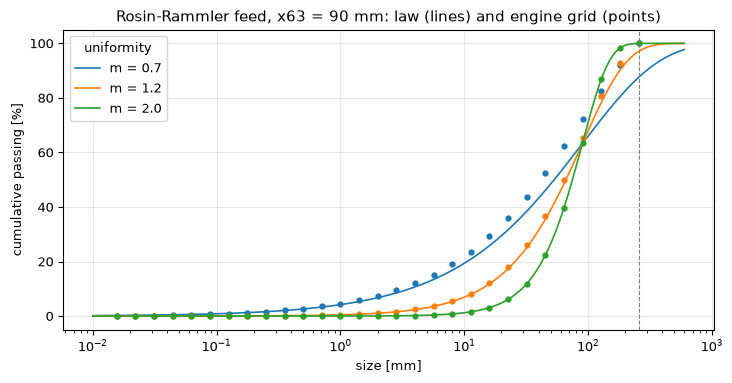

In [6]:
# Plot the textbook curve and the engine's grid values for each uniformity
sizes = np.logspace(-2, np.log10(600), 300)
fig, ax = plt.subplots()
for m, feed in feeds.items():
    line, = ax.plot(sizes, [law_passing(x, X63, m) * 100 for x in sizes], lw=1.2, label=f"m = {m}")
    ax.plot(edges, np.array(feed.passing) * 100, "o", ms=3.5, color=line.get_color())
ax.axvline(256, color="grey", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("size [mm]")
ax.set_ylabel("cumulative passing [%]")
ax.set_title("Rosin-Rammler feed, x63 = 90 mm: law (lines) and engine grid (points)")
ax.legend(title="uniformity")
fig.tight_layout()
plt.show()

The points leave their line at the right, where the law still has mass above the dashed 256 mm line and the engine's curve has already reached 100 percent: the wide feed's points sit visibly above its line over most of the range, the S01 feed's slightly, and the uniform feed's not at all. What the figure does not tell is which F80 a plant would measure; that depends on whether the real feed has a 256 mm top size, a fact the operating point must carry. It matters most for the secondary cone, where the feed top size is of the order of the crusher's intake.

**Step 2, how x63 moves F80 at fixed m.** The last step varies the characteristic size of a feed with the S01 uniformity, from 30 to 250 mm, and sets the engine's F80 against the textbook's. It shows where the truncation starts to matter.

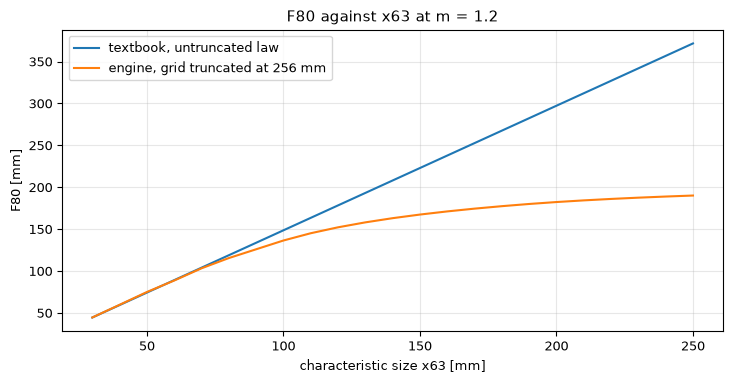

F80 at x63 = 250 mm: engine 190.2 mm, textbook 371.7 mm


In [7]:
# Sweep x63 at the S01 uniformity: engine F80 against textbook F80
x63_values = np.linspace(30, 250, 23)
engine_f80 = [size_at_passing(make_feed(edges, x, M), 0.8) for x in x63_values]
textbook_f80 = [law_size_at(0.8, x, M) for x in x63_values]
fig, ax = plt.subplots()
ax.plot(x63_values, textbook_f80, label="textbook, untruncated law")
ax.plot(x63_values, engine_f80, label="engine, grid truncated at 256 mm")
ax.set_xlabel("characteristic size x63 [mm]")
ax.set_ylabel("F80 [mm]")
ax.set_title("F80 against x63 at m = 1.2")
ax.legend()
fig.tight_layout()
plt.show()
print("F80 at x63 = 250 mm: engine", round(engine_f80[-1], 1), "mm, textbook", round(textbook_f80[-1], 1), "mm")

Below an x63 of about 60 mm the two lines are almost the same line. Above it they separate, and at x63 = 250 mm the engine's F80 is 190.2 mm against a textbook value of 371.7 mm, because the feed then has 35.7 percent of its mass beyond the grid. The engine's curve flattens: raising x63 further barely raises its F80, since only the part below 256 mm counts. A user who dials a coarse feed into the studio should read the F80 the studio reports, not the one the law suggests, and should treat a feed whose law places much mass above 256 mm as outside what the grid can represent.

## Results

**Answer:** x63 sets the scale of the feed and m its spread, and both move F80: at x63 = 90 mm the closed-form F80 is 177.62, 133.80 and 114.18 mm for m = 0.7, 1.2 and 2.0. The engine reports 117.66, 126.03 and 115.62 mm, because its grid stops at 256 mm and the law's mass above that size (12.50, 3.00 and 0.03 percent) is dropped and the rest renormalised. For the reference feed of S01 the engine's F80 is 126.03 mm, 7.77 mm below the textbook 133.80 mm, and at x63 = 250 mm the difference grows to 181.5 mm.

The figures separate two things that look alike. The first shows the engine's points on the law's line up to the cut, so the discretisation itself is sound. The second shows the cut growing with x63. A validator would conclude that F80 in this product is the F80 of the feed as the grid sees it, and that a feed with more than a few percent of its mass above 256 mm needs a different top size. The next notebook separates the interpolation error from this truncation error.

## Summary

A Rosin-Rammler feed is two numbers, and the engine turns them into 28 class masses. The textbook F80 and the engine's F80 differ by the mass beyond the 256 mm top of the grid, which is 3 percent for the reference feed and grows quickly with x63 and with a wide spread. Reading F80 from the engine, never from the formula, keeps the number consistent with the product size computed from the same grid. Notebook 02 shows how well the interpolation itself reads a size from the grid.

## References

- Rosin, P., Rammler, E. (1933), The laws governing the fineness of powdered coal, Journal of the Institute of Fuel 7, 29-36. https://cir.nii.ac.jp/crid/1572543024341127296
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193